# Notebook 02-R · Resumen del EDA con datos crudos
**Proyecto:** desnutrición crónica infantil con ENDES 2025 y XGBoost · IS-484 · UNSCH

Versión **corta** del notebook `02_EDA_Datos_Crudos`: los puntos clave en el mismo orden y solo los gráficos que sirven para comprobar cada hallazgo. Todo sobre los datos **crudos** (sin limpiar); cuando se muestra una versión "sin códigos especiales", es una copia solo para comparar.

| # | Punto clave | Evidencia |
|---|---|---|
| 1 | Qué contiene el dataset | tabla de tipos |
| 2 | Valores vacíos | gráfico de barras |
| 3 | Códigos especiales | barras + antes/después |
| 4 | Atípicos y reglas lógicas | tabla |
| 5 | Estadísticos descriptivos | tabla |
| 6 | Variable objetivo | histograma + balance |
| 7 | Quiénes están más afectados | prevalencias + edad |
| 8 | Relación con el objetivo | dispersión |
| 9 | Correlación | barras Pearson vs. Spearman |
| 10 | División train/test | tabla |
| 11 | Descenso de gradiente | curvas |
| 12 | Regresión lineal (Semana 05) | recta, métricas, real vs. predicho |
| 13 | Hallazgos y plan de limpieza | tabla |

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit, ShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11})
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 50)
AZUL, NARANJA, ROJO, GRIS, VERDE = "#4C78A8", "#F58518", "#E45756", "#9D9D9D", "#54A24B"

RAIZ = Path.cwd().parent if Path.cwd().name == "2 notebooks" else Path.cwd()
SALIDA = RAIZ / "3 datos_procesados"
df = pd.read_csv(SALIDA / "dataset_integrado_crudo.csv", dtype={"caseid": str, "hhid": str})
dic = pd.read_csv(SALIDA / "diccionario_variables.csv")

FEATURES = dic.loc[dic.rol == "feature", "nombre"].tolist()
CATEG = dic.loc[(dic.rol == "feature") & (dic.tipo == "categórica"), "nombre"].tolist()
NUM = [c for c in FEATURES if c not in CATEG]
CODIGOS = {r.nombre: [int(float(x)) for x in str(r.codigos_a_nan).split(",") if x.strip()]
           for r in dic.itertuples() if isinstance(r.codigos_a_nan, str) and r.codigos_a_nan.strip()}

ORDINALES = ["quintil_riqueza", "nivel_educativo_madre", "nivel_anemia_nino", "tamano_percibido_nacer", "diarrea_2sem", "tos_2sem"]
CONTINUAS = ["edad_madre", "edad_primer_parto", "peso_nacer_g", "talla_madre_x10", "imc_madre_x100",
             "altitud_msnm", "hacinamiento", "intervalo_nac_previo_meses"]
DISCRETAS = ["edad_meses", "orden_nacimiento", "visitas_prenatales", "n_controles_cred", "meses_lactancia", "n_menores_5_hogar"]


def naturaleza(c):
    return ("nominal" if c in CATEG else "ordinal" if c in ORDINALES else "continua" if c in CONTINUAS
            else "discreta" if c in DISCRETAS else "binaria")


def sin_codigos(serie):
    return serie.where(~serie.isin(CODIGOS.get(serie.name, [])))


dr = df[df["haz"].notna()].reset_index(drop=True)          # niños con objetivo válido
dr["desnutricion_cronica"] = dr["desnutricion_cronica"].astype(int)
PREV = dr["desnutricion_cronica"].mean() * 100
print(f"{len(df):,} niños | {len(FEATURES)} features | con objetivo válido: {len(dr):,} | prevalencia: {PREV:.1f} %")

18,841 niños | 42 features | con objetivo válido: 18,023 | prevalencia: 11.9 %


## 1. Qué contiene el dataset

In [2]:
tipos = pd.Series({c: naturaleza(c) for c in FEATURES})
resumen = pd.DataFrame({"n": tipos.value_counts(), "variables": tipos.groupby(tipos).apply(lambda s: ", ".join(s.index[:6]) + (" …" if len(s) > 6 else ""))})
resumen.reindex(["continua", "discreta", "ordinal", "binaria", "nominal"])

,n,variables
continua,8,"intervalo_nac_previo_meses, peso_nacer_g, edad..."
discreta,6,"edad_meses, orden_nacimiento, visitas_prenatal..."
ordinal,6,"nivel_anemia_nino, tamano_percibido_nacer, dia..."
binaria,13,"sexo_nino, hierro_embarazo, lactancia_exclusiv..."
nominal,9,"lugar_parto, lengua_materna_madre, departament..."


**Lectura:** 18 841 niños y 42 *features* (8 continuas, 6 discretas, 6 ordinales, 13 binarias, 9 nominales). Casi todo es un número, pero muchos números son **códigos**, no cantidades.

## 2. Valores vacíos

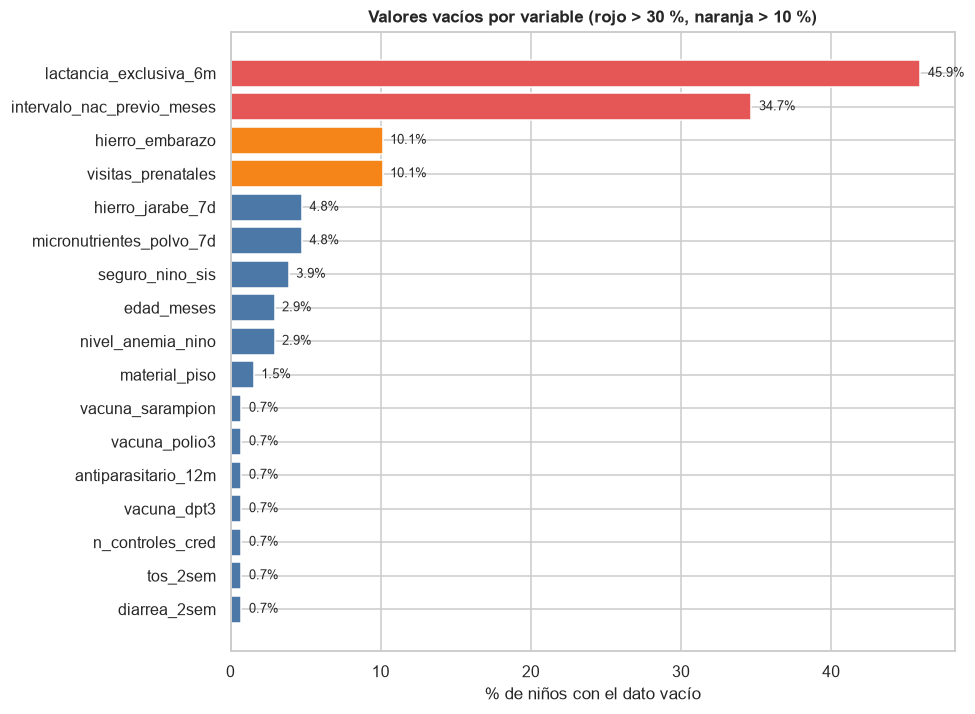

Features completas: 25 de 42


In [3]:
vacios = df[FEATURES].isna().mean().mul(100).sort_values(ascending=False)
con_vacios = vacios[vacios > 0]
fig, ax = plt.subplots(figsize=(9, 0.32 * len(con_vacios) + 1.2))
colores = [ROJO if v > 30 else NARANJA if v > 10 else AZUL for v in con_vacios.values]
ax.barh(con_vacios.index[::-1], con_vacios.values[::-1], color=colores[::-1])
for i, v in enumerate(con_vacios.values[::-1]):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=8.5)
ax.set_xlabel("% de niños con el dato vacío")
ax.set_title("Valores vacíos por variable (rojo > 30 %, naranja > 10 %)")
plt.tight_layout()
plt.show()
print(f"Features completas: {int((vacios == 0).sum())} de {len(FEATURES)}")

**Lectura:** 25 de 42 features están completas. Los vacíos grandes son **por diseño**: lactancia exclusiva (solo desde los 6 meses), intervalo entre hijos (vacío en primogénitos) y controles/hierro del embarazo (solo se preguntan por el hijo menor de cada madre).

## 3. Códigos especiales (el problema más importante)
Los "no sabe / no se pesó / no medida" vienen como **números** (9996, 9998, 9999, 98, 8, 9). Si no se convierten en `NaN`, el modelo los lee como cantidades reales.

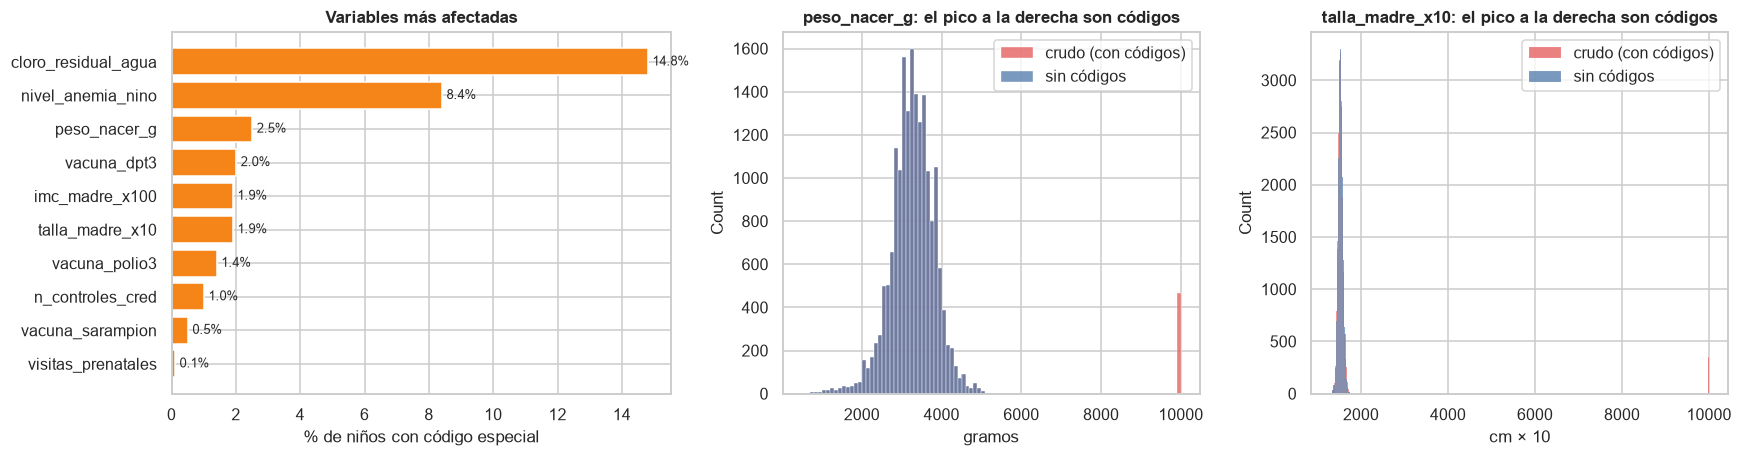

,media cruda,media sin códigos,distorsión %
talla_madre_x10,1685.8,1527.5,10.4
peso_nacer_g,3411.4,3244.4,5.1
imc_madre_x100,2975.1,2840.6,4.7


In [4]:
filas = [{"variable": v, "n": int(df[v].isin(c).sum())} for v, c in CODIGOS.items() if df[v].isin(c).sum() > 0]
cod = pd.DataFrame(filas).sort_values("n", ascending=False).head(10)
cod["%"] = (100 * cod["n"] / len(df)).round(1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), gridspec_kw={"width_ratios": [1.2, 1, 1]})
axes[0].barh(cod["variable"][::-1], cod["%"][::-1], color=NARANJA)
for i, v in enumerate(cod["%"][::-1]):
    axes[0].text(v + 0.15, i, f"{v}%", va="center", fontsize=8.5)
axes[0].set_xlabel("% de niños con código especial")
axes[0].set_title("Variables más afectadas")
for ax, var, unidad, ancho in zip(axes[1:], ["peso_nacer_g", "talla_madre_x10"], ["gramos", "cm × 10"], [100, 25]):
    sns.histplot(df[var].dropna(), binwidth=ancho, color=ROJO, ax=ax, label="crudo (con códigos)")
    sns.histplot(sin_codigos(df[var]).dropna(), binwidth=ancho, color=AZUL, ax=ax, label="sin códigos")
    ax.set_title(f"{var}: el pico a la derecha son códigos")
    ax.set_xlabel(unidad)
    ax.legend()
plt.tight_layout()
plt.show()

media = pd.DataFrame({"media cruda": [df[v].mean() for v in ["talla_madre_x10", "peso_nacer_g", "imc_madre_x100"]],
                      "media sin códigos": [sin_codigos(df[v]).mean() for v in ["talla_madre_x10", "peso_nacer_g", "imc_madre_x100"]]},
                     index=["talla_madre_x10", "peso_nacer_g", "imc_madre_x100"]).round(1)
media["distorsión %"] = ((media.iloc[:, 0] / media.iloc[:, 1] - 1) * 100).round(1)
media

**Lectura:** 20 variables llevan códigos. `cloro_residual_agua` (14.8 %, incluye un código **6 que no figura en el diccionario INEI**) y `nivel_anemia_nino` (8.4 %) son las más afectadas. Sin convertirlos, la talla media de la madre sale 168.6 cm en lugar de 152.8 cm.

## 4. Atípicos y reglas lógicas

In [5]:
d_ = df
reglas = [
    ("edad_madre fuera de 12-49 años", ~d_.edad_madre.between(12, 49) & d_.edad_madre.notna()),
    ("edad al primer parto mayor que la edad de la madre", d_.edad_primer_parto > d_.edad_madre),
    ("peso al nacer fuera de 500-6 000 g (sin códigos)", ~d_.peso_nacer_g.between(500, 6000) & ~d_.peso_nacer_g.isin([9996, 9998]) & d_.peso_nacer_g.notna()),
    ("IMC de la madre fuera de 12-50 (sin códigos)", ~d_.imc_madre_x100.between(1200, 5000) & ~d_.imc_madre_x100.isin([9998, 9999]) & d_.imc_madre_x100.notna()),
    ("meses de lactancia > edad del niño (sin 94/98)", (d_.meses_lactancia > d_.edad_meses) & ~d_.meses_lactancia.isin([94, 98])),
    ("hogar con 0 menores de 5 años (hay un niño)", d_.n_menores_5_hogar == 0),
    ("hacinamiento > 8 personas por dormitorio", d_.hacinamiento > 8),
    ("puntaje Z fuera de ±6", ~d_.haz.between(-6, 6) & d_.haz.notna()),
]
t_reglas = pd.DataFrame([{"regla lógica": n, "niños": int(m.sum()), "%": round(100 * m.mean(), 2)} for n, m in reglas])

filas = []
for var in ["peso_nacer_g", "talla_madre_x10", "imc_madre_x100"]:
    s = df[var].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    fuera = s[(s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))]
    filas.append({"regla lógica": f"RIC en {var}", "niños": len(fuera), "%": round(100 * len(fuera) / len(s), 2),
                  "de ellos, códigos especiales": int(fuera.isin(CODIGOS.get(var, [])).sum())})
pd.concat([t_reglas, pd.DataFrame(filas)], ignore_index=True).fillna("")

,regla lógica,niños,%,"de ellos, códigos especiales"
0,edad_madre fuera de 12-49 años,0,0.00,
1,edad al primer parto mayor que la edad de la m...,0,0.00,
2,peso al nacer fuera de 500-6 000 g (sin códigos),0,0.00,
3,IMC de la madre fuera de 12-50 (sin códigos),18,0.10,
4,meses de lactancia > edad del niño (sin 94/98),3,0.02,
5,hogar con 0 menores de 5 años (hay un niño),45,0.24,
6,hacinamiento > 8 personas por dormitorio,69,0.37,
7,puntaje Z fuera de ±6,0,0.00,
8,RIC en peso_nacer_g,943,5.01,466.0
9,RIC en talla_madre_x10,546,2.90,352.0


**Lectura:** las reglas lógicas casi no encuentran errores (< 0.4 %). El RIC marca muchos "atípicos", pero una parte grande son **los códigos especiales** (peso: 466 de 943; talla: 352 de 546): primero se convierten los códigos y después se mira el RIC.

## 5. Estadísticos descriptivos (crudos)

In [6]:
filas = []
for var in ["haz", "peso_nacer_g", "talla_madre_x10", "edad_madre", "altitud_msnm"]:
    s = df[var].dropna()
    filas.append({"variable": var + (" ⚠" if var in CODIGOS else ""), "media": s.mean(), "mediana": s.median(), "moda": s.mode().iloc[0],
                  "desv. estándar": s.std(), "mínimo": s.min(), "máximo": s.max(), "asimetría": s.skew()})
pd.DataFrame(filas).set_index("variable").round(2)

,media,mediana,moda,desv. estándar,mínimo,máximo,asimetría
variable,,,,,,,
haz,-0.83,-0.83,-1.13,1.03,-5.72,3.98,-0.06
peso_nacer_g ⚠,3411.42,3280.00,3200.00,1182.34,500.00,9998.00,4.14
talla_madre_x10 ⚠,1685.82,1527.00,9999.00,1148.44,1294.00,9999.00,7.08
edad_madre,30.92,31.00,32.00,6.97,13.00,49.00,0.04
altitud_msnm,1197.18,364.00,27.00,1376.55,1.00,4500.00,0.84


**Lectura:** donde hay códigos (⚠) las estadísticas engañan: en la talla de la madre la **moda es 9999** y la media supera en 16 cm a la mediana. El `haz` es casi simétrico con media −0.83 y desviación 1.03.

## 6. Variable objetivo

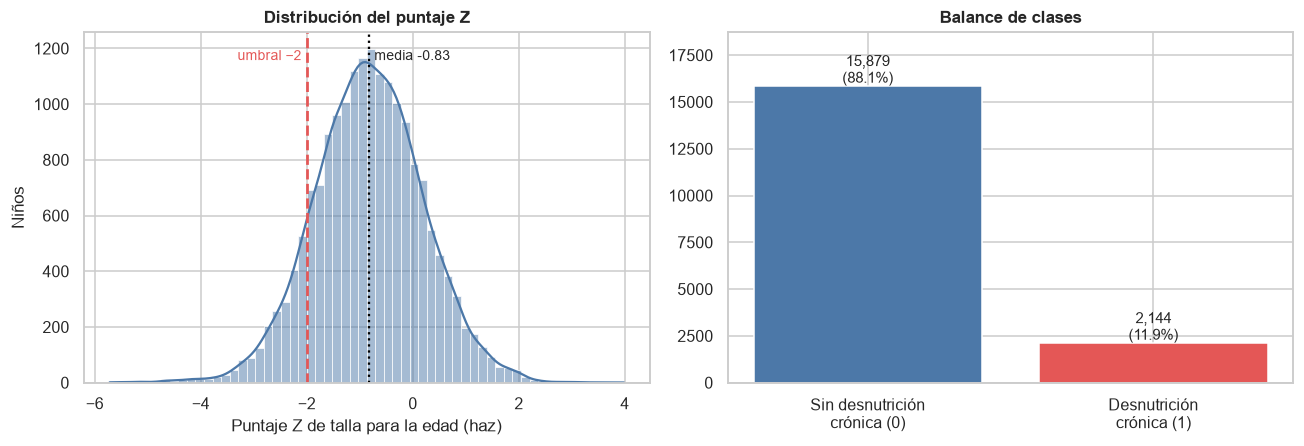

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.histplot(dr["haz"], bins=60, kde=True, color=AZUL, ax=axes[0])
axes[0].axvline(-2, color=ROJO, ls="--", lw=1.8)
axes[0].axvline(dr["haz"].mean(), color="black", ls=":", lw=1.5)
axes[0].text(-2.1, axes[0].get_ylim()[1] * 0.92, "umbral −2", color=ROJO, ha="right", fontsize=9)
axes[0].text(dr["haz"].mean() + 0.1, axes[0].get_ylim()[1] * 0.92, f"media {dr['haz'].mean():.2f}", fontsize=9)
axes[0].set_xlabel("Puntaje Z de talla para la edad (haz)")
axes[0].set_ylabel("Niños")
axes[0].set_title("Distribución del puntaje Z")

conteo = dr["desnutricion_cronica"].value_counts().sort_index()
barras = axes[1].bar(["Sin desnutrición\ncrónica (0)", "Desnutrición\ncrónica (1)"], conteo.values, color=[AZUL, ROJO])
for b, v in zip(barras, conteo.values):
    axes[1].text(b.get_x() + b.get_width() / 2, v + 150, f"{v:,}\n({100 * v / len(dr):.1f}%)", ha="center", fontsize=10)
axes[1].set_ylim(0, conteo.max() * 1.18)
axes[1].set_title("Balance de clases")
plt.tight_layout()
plt.show()

**Lectura:** 18 023 niños tienen objetivo válido (818 no). El 11.9 % está por debajo de −2: problema **desbalanceado**; la exactitud no sirve (decir siempre "no" acierta 88 %). Se usará AUC-PR, recall, F1 y `scale_pos_weight`.

## 7. Quiénes están más afectados

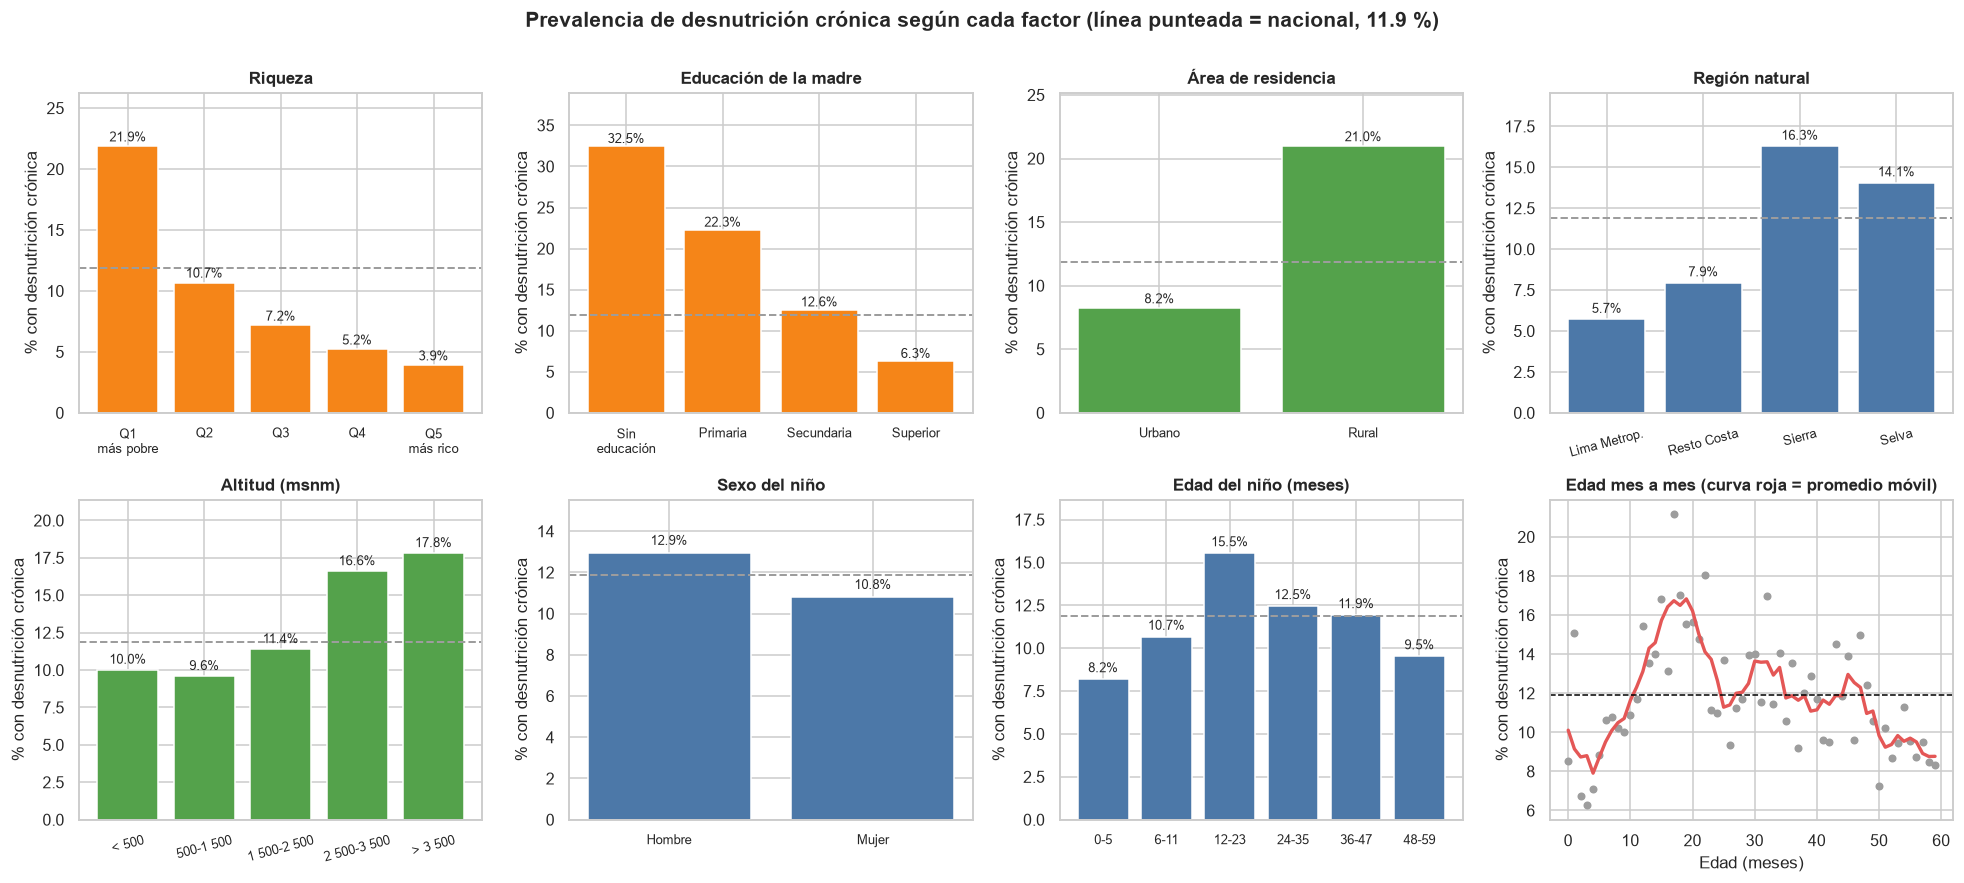

In [8]:
ETQ = {
    "sexo_nino": {1: "Hombre", 2: "Mujer"}, "area_residencia": {1: "Urbano", 2: "Rural"},
    "region_natural": {1: "Lima Metrop.", 2: "Resto Costa", 3: "Sierra", 4: "Selva"},
    "quintil_riqueza": {1: "Q1\nmás pobre", 2: "Q2", 3: "Q3", 4: "Q4", 5: "Q5\nmás rico"},
    "nivel_educativo_madre": {0: "Sin\neducación", 1: "Primaria", 2: "Secundaria", 3: "Superior"},
}


def prevalencia(ax, serie, titulo, etiquetas=None, color=AZUL, rotar=0):
    t = dr.groupby(serie, observed=True)["desnutricion_cronica"].agg(["mean", "size"])
    t["mean"] *= 100
    nombres = [etiquetas.get(i, str(i)) for i in t.index] if etiquetas else [str(i) for i in t.index]
    ax.bar(nombres, t["mean"], color=color)
    for i, m in enumerate(t["mean"]):
        ax.text(i, m + 0.4, f"{m:.1f}%", ha="center", fontsize=8.5)
    ax.axhline(PREV, color=GRIS, ls="--", lw=1.3)
    ax.set_title(titulo)
    ax.set_ylabel("% con desnutrición crónica")
    ax.tick_params(axis="x", rotation=rotar, labelsize=8.5)
    ax.set_ylim(0, t["mean"].max() * 1.2)


alt = pd.cut(dr["altitud_msnm"], [0, 500, 1500, 2500, 3500, 5000], labels=["< 500", "500-1 500", "1 500-2 500", "2 500-3 500", "> 3 500"])
edad = pd.cut(dr["edad_meses"], [-1, 5, 11, 23, 35, 47, 59], labels=["0-5", "6-11", "12-23", "24-35", "36-47", "48-59"])

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
prevalencia(axes[0, 0], dr["quintil_riqueza"], "Riqueza", ETQ["quintil_riqueza"], color=NARANJA)
prevalencia(axes[0, 1], dr["nivel_educativo_madre"], "Educación de la madre", ETQ["nivel_educativo_madre"], color=NARANJA)
prevalencia(axes[0, 2], dr["area_residencia"], "Área de residencia", ETQ["area_residencia"], color=VERDE)
prevalencia(axes[0, 3], dr["region_natural"], "Región natural", ETQ["region_natural"], rotar=15)
prevalencia(axes[1, 0], alt, "Altitud (msnm)", color=VERDE, rotar=15)
prevalencia(axes[1, 1], dr["sexo_nino"], "Sexo del niño", ETQ["sexo_nino"])
prevalencia(axes[1, 2], edad, "Edad del niño (meses)")
por_mes = dr.groupby("edad_meses")["desnutricion_cronica"].mean().mul(100)
axes[1, 3].scatter(por_mes.index, por_mes.values, s=18, color=GRIS)
axes[1, 3].plot(por_mes.rolling(5, center=True, min_periods=1).mean(), color=ROJO, lw=2.2)
axes[1, 3].axhline(PREV, color="black", ls="--", lw=1)
axes[1, 3].set_xlabel("Edad (meses)")
axes[1, 3].set_ylabel("% con desnutrición crónica")
axes[1, 3].set_title("Edad mes a mes (curva roja = promedio móvil)")
fig.suptitle(f"Prevalencia de desnutrición crónica según cada factor (línea punteada = nacional, {PREV:.1f} %)", fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

**Lectura:** se concentra en pobreza (Q1 21.9 % frente a Q5 3.9 %), baja educación materna (32.5 % sin educación), zonas rurales (21.0 % frente a 8.2 %), Sierra y Selva, y sobre los 2 500 m. Los varones tienen algo más (12.9 % frente a 10.8 %). **La edad no es lineal:** sube hasta 15.5 % entre los 12 y 23 meses y luego baja a 9.5 %.

## 8. Relación con el objetivo (dispersión)
Se compara la talla de la madre y el peso al nacer contra el `haz`: en **crudo** y **sin códigos** (copia).

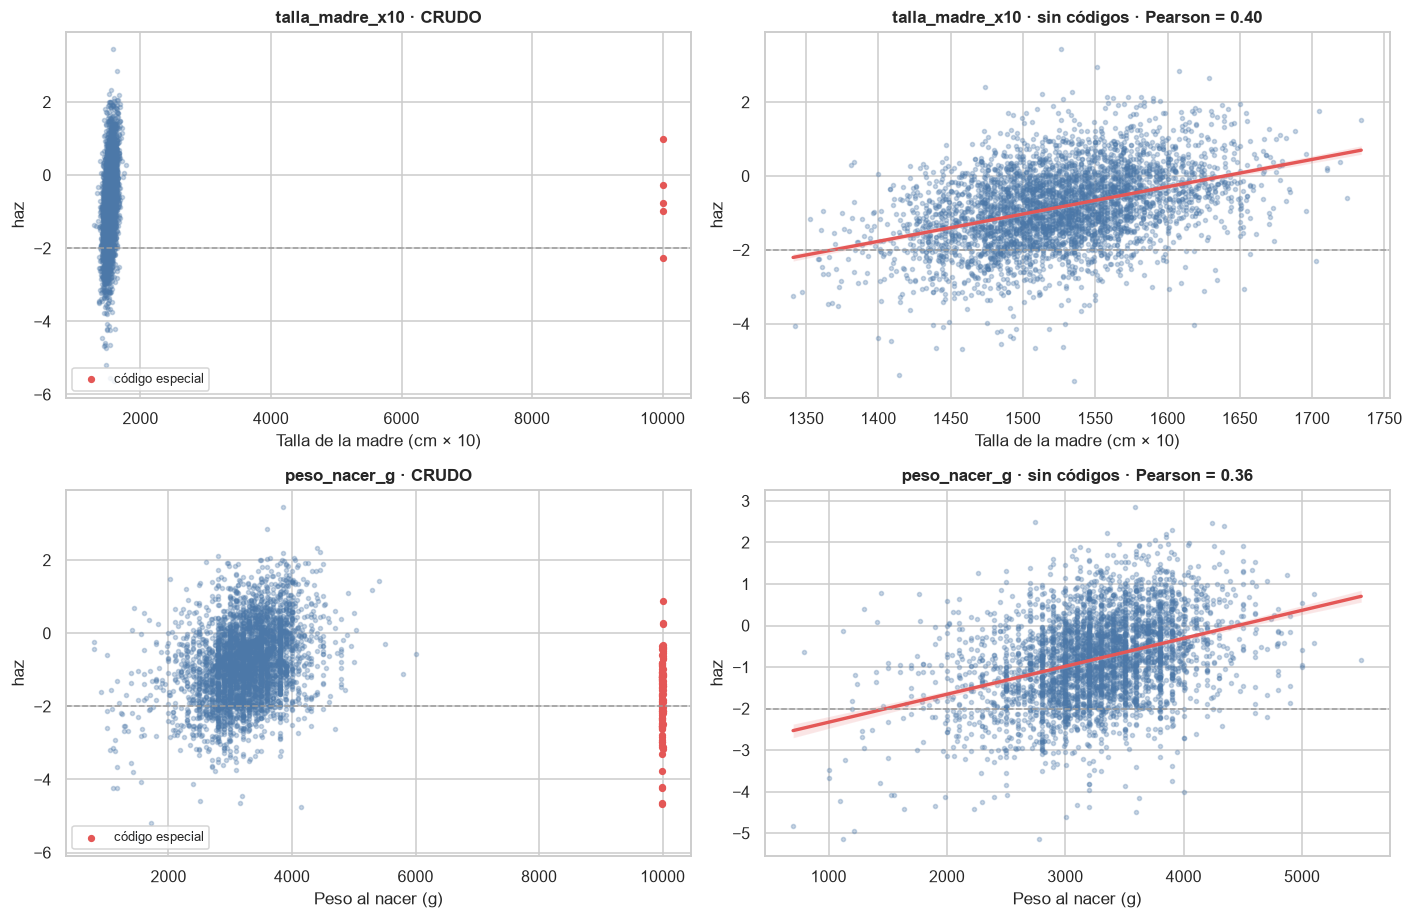

In [9]:
muestra = dr.sample(4000, random_state=42)
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
for fila, (var, nombre) in enumerate([("talla_madre_x10", "Talla de la madre (cm × 10)"), ("peso_nacer_g", "Peso al nacer (g)")]):
    ax = axes[fila, 0]
    ax.scatter(muestra[var], muestra["haz"], s=7, alpha=0.3, color=AZUL)
    malos = muestra[muestra[var].isin(CODIGOS[var])]
    ax.scatter(malos[var], malos["haz"], s=14, color=ROJO, label="código especial")
    ax.axhline(-2, color=GRIS, ls="--", lw=1)
    ax.set_title(f"{var} · CRUDO")
    ax.set_xlabel(nombre)
    ax.set_ylabel("haz")
    ax.legend(fontsize=8.5, loc="lower left")
    limpio = pd.DataFrame({"x": sin_codigos(dr[var]), "haz": dr["haz"]}).dropna().sample(4000, random_state=42)
    sns.regplot(data=limpio, x="x", y="haz", ax=axes[fila, 1], scatter_kws={"s": 7, "alpha": 0.3, "color": AZUL}, line_kws={"color": ROJO, "lw": 2.2})
    axes[fila, 1].axhline(-2, color=GRIS, ls="--", lw=1)
    axes[fila, 1].set_title(f"{var} · sin códigos · Pearson = {limpio['x'].corr(limpio['haz']):.2f}")
    axes[fila, 1].set_xlabel(nombre)
    axes[fila, 1].set_ylabel("haz")
plt.tight_layout()
plt.show()

**Lectura:** en crudo los códigos (puntos rojos) quedan lejísimos de la nube real y aplastan el gráfico. Sin ellos se ve la relación esperada: madres más altas y bebés más pesados tienen niños con mayor `haz`.

## 9. Correlación con el `haz`

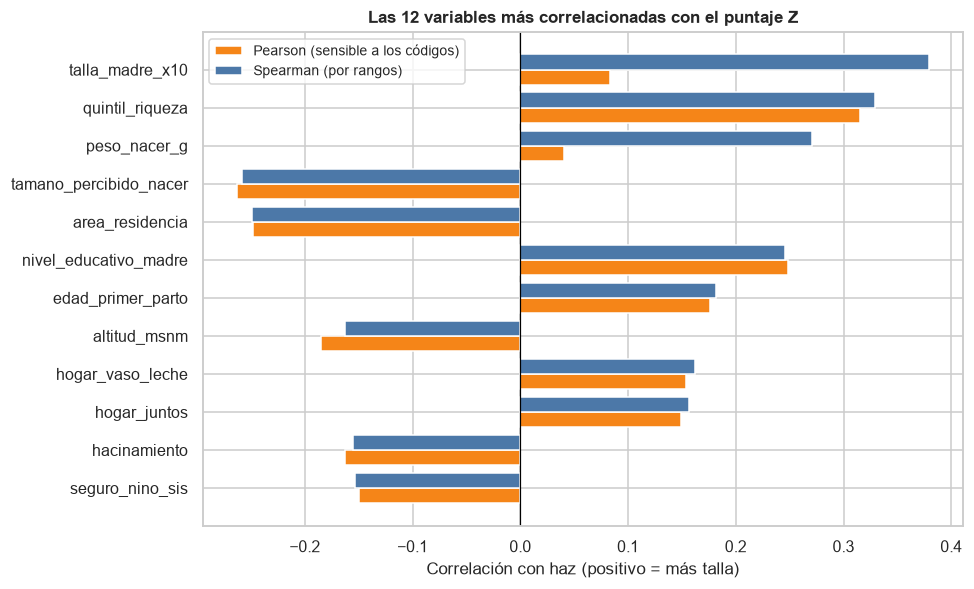

In [10]:
pear = dr[NUM].corrwith(dr["haz"], method="pearson")
spea = dr[NUM].corrwith(dr["haz"], method="spearman")
cor = pd.DataFrame({"Pearson": pear, "Spearman": spea})
top = cor.reindex(cor["Spearman"].abs().sort_values(ascending=False).index).head(12)[::-1]

fig, ax = plt.subplots(figsize=(9, 5.5))
y_ = np.arange(len(top))
ax.barh(y_ - 0.2, top["Pearson"], height=0.4, color=NARANJA, label="Pearson (sensible a los códigos)")
ax.barh(y_ + 0.2, top["Spearman"], height=0.4, color=AZUL, label="Spearman (por rangos)")
ax.set_yticks(y_)
ax.set_yticklabels(top.index)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Correlación con haz (positivo = más talla)")
ax.set_title("Las 12 variables más correlacionadas con el puntaje Z")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

**Lectura:** talla de la madre (+0.38), riqueza (+0.33), peso al nacer (+0.27), tamaño percibido al nacer (−0.26), área rural (−0.25) y educación de la madre (+0.25). **Pearson y Spearman discrepan** donde hay códigos (talla materna 0.08 frente a 0.38). Los programas sociales parecen "negativos" porque llegan a los hogares más pobres.

## 10. División train/test: ¿al azar o por conglomerado?

In [11]:
X_all, y_reg, y_cls, grupos = dr[FEATURES], dr["haz"], dr["desnutricion_cronica"], dr["conglomerado"]
res = []
for semilla in [1, 2, 3]:
    for nombre, div in [("Al azar por niño", ShuffleSplit(n_splits=1, test_size=0.2, random_state=semilla)),
                        ("Por conglomerado", GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=semilla))]:
        tr_, te_ = next(div.split(X_all, y_reg, groups=grupos))
        reg = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, random_state=42).fit(X_all.iloc[tr_], y_reg.iloc[tr_])
        cls = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=42).fit(X_all.iloc[tr_], y_cls.iloc[tr_])
        res.append({"división": nombre, "R² (regresión)": r2_score(y_reg.iloc[te_], reg.predict(X_all.iloc[te_])),
                    "AUC (clasificación)": roc_auc_score(y_cls.iloc[te_], cls.predict_proba(X_all.iloc[te_])[:, 1])})
pd.DataFrame(res).groupby("división").mean().round(3)

,R² (regresión),AUC (clasificación)
división,,
Al azar por niño,0.338,0.796
Por conglomerado,0.339,0.803


**Lectura:** en estos datos la diferencia es mínima (R² 0.338 frente a 0.339; AUC 0.796 frente a 0.803): no hay fuga apreciable. Se mantiene la división **por conglomerado** por prudencia. Esto también deja una referencia: R² ≈ 0.34 y AUC ≈ 0.80 con árboles potenciados sobre datos crudos.

## 11. Función de error y descenso de gradiente (Semana 03)
Ejemplo con `quintil_riqueza` (estandarizada) para predecir el `haz`.

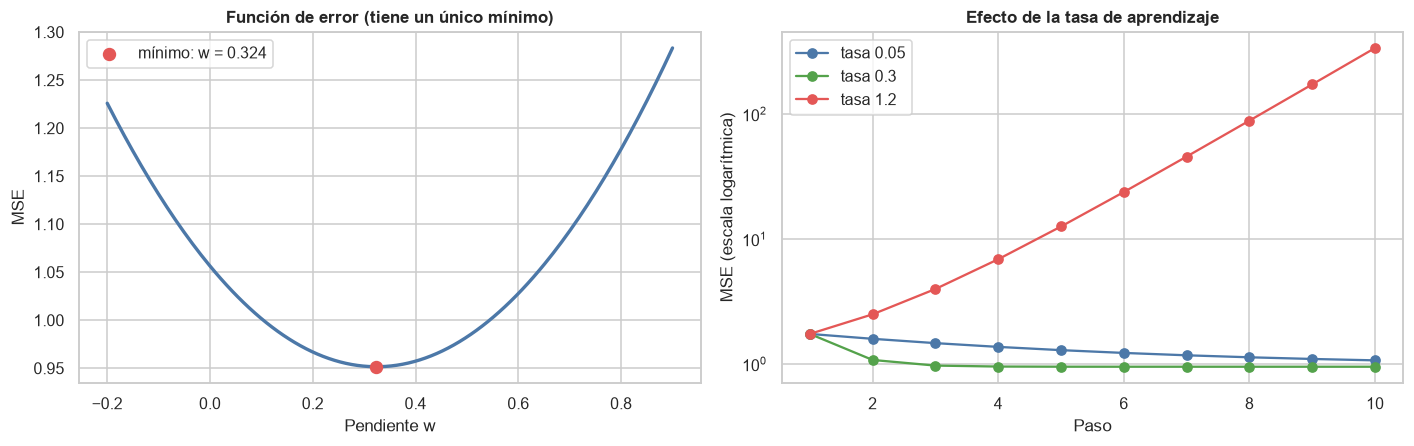

scikit-learn: w = 0.3238, b = -0.8277 | descenso (tasa 0.3, 10 pasos): w = 0.3238, b = -0.8276


In [12]:
x = ((dr["quintil_riqueza"] - dr["quintil_riqueza"].mean()) / dr["quintil_riqueza"].std()).values
yv, n = dr["haz"].values, len(dr)
sk = LinearRegression().fit(x.reshape(-1, 1), yv)
w_opt, b_opt = sk.coef_[0], sk.intercept_


def descenso(tasa, pasos=10):
    w = b = 0.0
    mse_h = []
    for _ in range(pasos):
        e = w * x + b - yv
        mse_h.append(np.mean(e ** 2))
        w, b = w - tasa * (2 / n) * np.sum(e * x), b - tasa * (2 / n) * np.sum(e)
    return mse_h, w, b


fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ws = np.linspace(-0.2, 0.9, 200)
axes[0].plot(ws, [np.mean((w * x + b_opt - yv) ** 2) for w in ws], color=AZUL, lw=2.2)
axes[0].scatter([w_opt], [np.mean((w_opt * x + b_opt - yv) ** 2)], color=ROJO, s=60, zorder=5, label=f"mínimo: w = {w_opt:.3f}")
axes[0].set_xlabel("Pendiente w")
axes[0].set_ylabel("MSE")
axes[0].set_title("Función de error (tiene un único mínimo)")
axes[0].legend()
for t, color in zip([0.05, 0.3, 1.2], [AZUL, VERDE, ROJO]):
    h, w_f, b_f = descenso(t)
    axes[1].plot(range(1, 11), h, marker="o", color=color, label=f"tasa {t}")
axes[1].set_yscale("log")
axes[1].set_xlabel("Paso")
axes[1].set_ylabel("MSE (escala logarítmica)")
axes[1].set_title("Efecto de la tasa de aprendizaje")
axes[1].legend()
plt.tight_layout()
plt.show()
_, w3, b3 = descenso(0.3)
print(f"scikit-learn: w = {w_opt:.4f}, b = {b_opt:.4f} | descenso (tasa 0.3, 10 pasos): w = {w3:.4f}, b = {b3:.4f}")

**Lectura:** con tasa 0.3 el descenso llega al mismo resultado que scikit-learn; con 0.05 es demasiado lento y con 1.2 **diverge**. En XGBoost es el `learning_rate`.

## 12. Regresión lineal sobre datos crudos (Semana 05)
División 80/20 por conglomerado (`random_state=42`). Estos números son la **línea base** para comparar con los datos limpios.

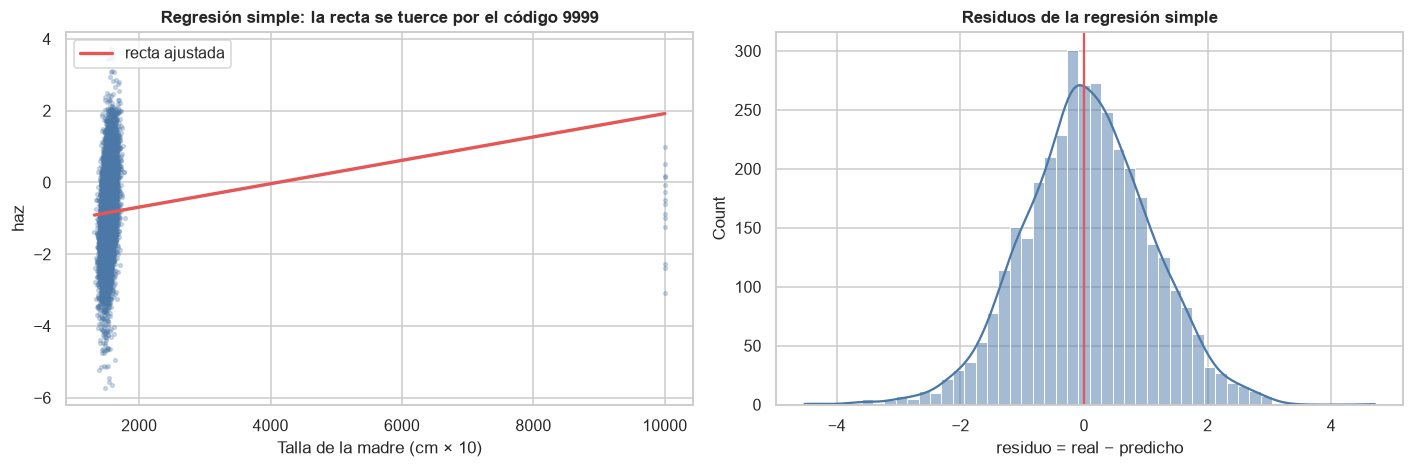

,MAE,RMSE,R²,R² ajustado
Regresión simple (talla materna),0.8089,1.0309,0.0028,0.0025


In [13]:
X, y = dr[FEATURES], dr["haz"]
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(X, y, groups=dr["conglomerado"]))
X_tr, X_te, y_tr, y_te = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]


def metricas(y_real, y_pred, p):
    n_ = len(y_real)
    mse, r2 = mean_squared_error(y_real, y_pred), r2_score(y_real, y_pred)
    return {"MAE": mean_absolute_error(y_real, y_pred), "RMSE": np.sqrt(mse), "R²": r2, "R² ajustado": 1 - (1 - r2) * (n_ - 1) / (n_ - p - 1)}


# 12.1 Regresión simple: haz ~ talla de la madre
simple = LinearRegression().fit(X_tr[["talla_madre_x10"]], y_tr)
pred_s = simple.predict(X_te[["talla_madre_x10"]])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].scatter(X_tr["talla_madre_x10"], y_tr, s=6, alpha=0.25, color=AZUL)
xs = np.array([X_tr["talla_madre_x10"].min(), 9999])
axes[0].plot(xs, simple.intercept_ + simple.coef_[0] * xs, color=ROJO, lw=2.2, label="recta ajustada")
axes[0].set_xlabel("Talla de la madre (cm × 10)")
axes[0].set_ylabel("haz")
axes[0].set_title("Regresión simple: la recta se tuerce por el código 9999")
axes[0].legend(loc="upper left")
sns.histplot(y_te - pred_s, bins=50, kde=True, color=AZUL, ax=axes[1])
axes[1].axvline(0, color=ROJO, lw=1.5)
axes[1].set_xlabel("residuo = real − predicho")
axes[1].set_title("Residuos de la regresión simple")
plt.tight_layout()
plt.show()
pd.DataFrame([metricas(y_te, pred_s, 1)], index=["Regresión simple (talla materna)"]).round(4)

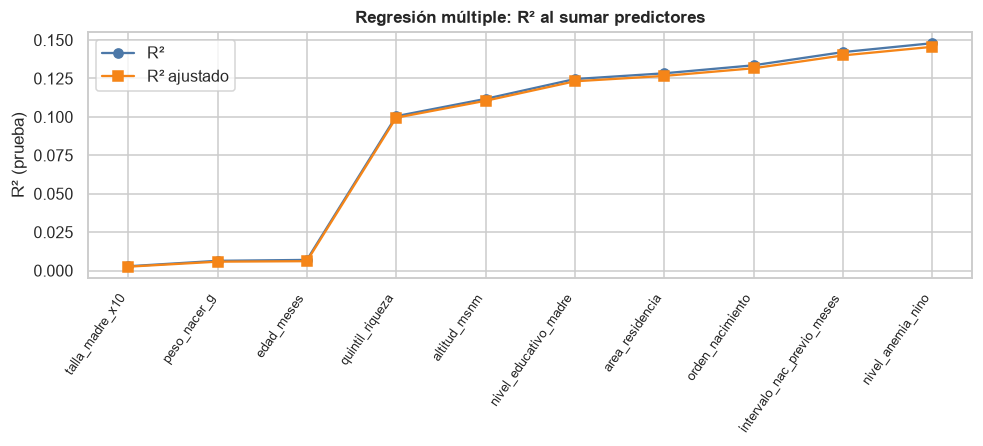

In [14]:
# 12.2 Regresión múltiple: R² al ir sumando predictores
orden_pred = ["talla_madre_x10", "peso_nacer_g", "edad_meses", "quintil_riqueza", "altitud_msnm",
              "nivel_educativo_madre", "area_residencia", "orden_nacimiento", "intervalo_nac_previo_meses", "nivel_anemia_nino"]
filas = []
for k in range(1, len(orden_pred) + 1):
    m = Pipeline([("imp", SimpleImputer(strategy="median")), ("lr", LinearRegression())]).fit(X_tr[orden_pred[:k]], y_tr)
    filas.append({"k": k, "se agrega": orden_pred[k - 1], **metricas(y_te, m.predict(X_te[orden_pred[:k]]), k)})
sec = pd.DataFrame(filas).set_index("k")

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(sec.index, sec["R²"], marker="o", color=AZUL, label="R²")
ax.plot(sec.index, sec["R² ajustado"], marker="s", color=NARANJA, label="R² ajustado")
ax.set_xticks(sec.index)
ax.set_xticklabels(sec["se agrega"], rotation=55, ha="right", fontsize=8.5)
ax.set_ylabel("R² (prueba)")
ax.set_title("Regresión múltiple: R² al sumar predictores")
ax.legend()
plt.tight_layout()
plt.show()

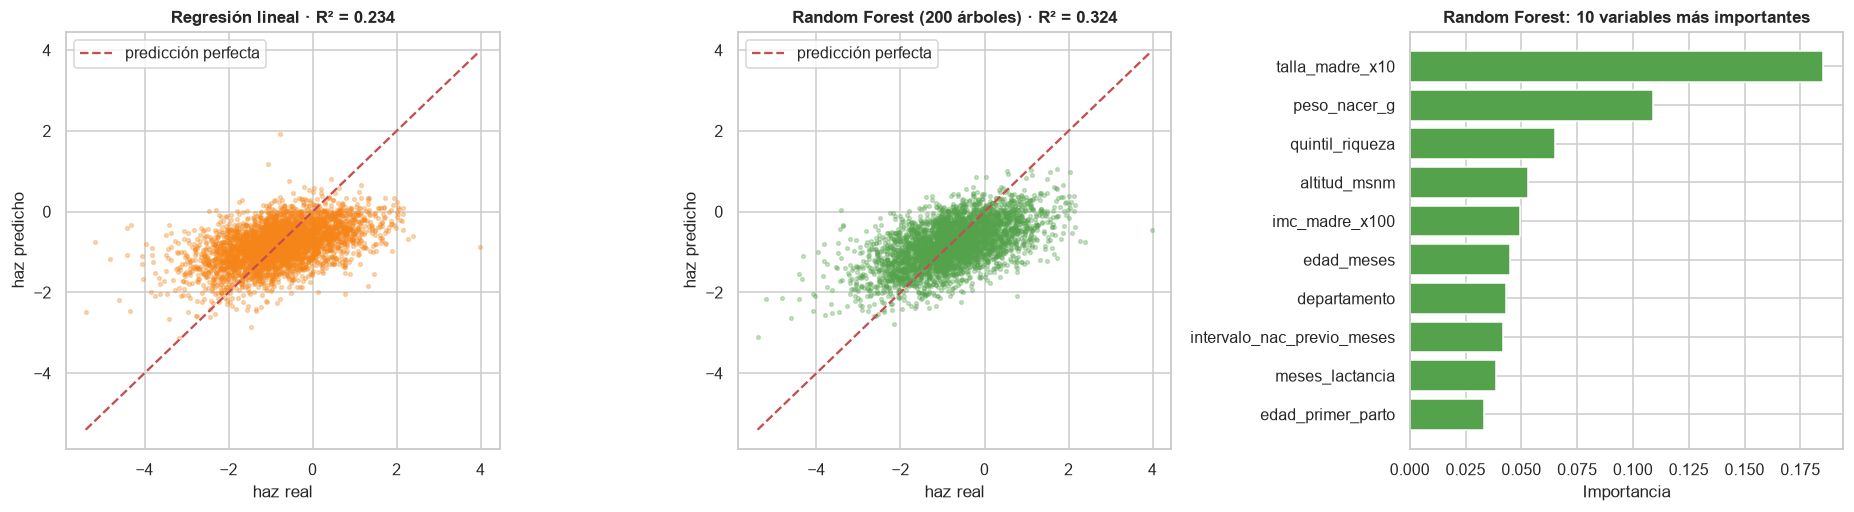

,MAE,RMSE,R²,R² ajustado
modelo,,,,
Referencia (media),0.8119,1.0337,-0.0025,-0.0144
Regresión lineal,0.7092,0.9033,0.2344,0.2253
Random Forest (200 árboles),0.6683,0.8488,0.3239,0.3160


In [15]:
# 12.3 Pipeline con las 42 variables: referencia vs. regresión lineal vs. Random Forest
preproc = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median"))]), NUM),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CATEG),
])
modelos = {"Referencia (media)": DummyRegressor(), "Regresión lineal": LinearRegression(),
           "Random Forest (200 árboles)": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)}
ajust, preds, filas = {}, {}, []
for nombre, mod in modelos.items():
    ajust[nombre] = Pipeline([("prep", preproc), ("model", mod)]).fit(X_tr, y_tr)
    preds[nombre] = ajust[nombre].predict(X_te)
    filas.append({"modelo": nombre, **metricas(y_te, preds[nombre], X_tr.shape[1])})
comparacion = pd.DataFrame(filas).set_index("modelo")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, nombre, color in zip(axes[:2], ["Regresión lineal", "Random Forest (200 árboles)"], [NARANJA, VERDE]):
    ax.scatter(y_te, preds[nombre], s=6, alpha=0.3, color=color)
    lim = [min(y_te.min(), preds[nombre].min()), max(y_te.max(), preds[nombre].max())]
    ax.plot(lim, lim, "r--", lw=1.5, label="predicción perfecta")
    ax.set_xlabel("haz real")
    ax.set_ylabel("haz predicho")
    ax.set_title(f"{nombre} · R² = {r2_score(y_te, preds[nombre]):.3f}")
    ax.legend()
rf = ajust["Random Forest (200 árboles)"]
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=rf.named_steps["prep"].get_feature_names_out())
base = imp.index.to_series().map(lambda n: next((c for c in CATEG if n.split("__", 1)[1].startswith(c + "_")), n.split("__", 1)[1]))
top = imp.groupby(base).sum().sort_values(ascending=False).head(10)[::-1]
axes[2].barh(top.index, top.values, color=VERDE)
axes[2].set_xlabel("Importancia")
axes[2].set_title("Random Forest: 10 variables más importantes")
plt.tight_layout()
plt.show()
comparacion.round(4)

**Lectura:** con talla materna sola el R² es ≈ 0 (el código 9999 distorsiona la recta); con 10 variables llega a 0.148. Con las 42 variables, la regresión lineal logra 0.234 y el **Random Forest 0.324** (RMSE 0.849 frente a 1.034 de la referencia): gana porque capta no linealidades (edad) y tolera los códigos especiales. Las variables más importantes (talla materna, peso al nacer, riqueza, altitud, IMC) coinciden con las correlaciones.

## 13. Hallazgos y plan de limpieza

In [16]:
pd.DataFrame([
    ("Códigos especiales", "20 variables con 9996-9999, 98, 8, 9 que parecen datos", "Convertir a NaN variable por variable"),
    ("Código sin documentar", "cloro_residual_agua = 6 (1 178 niños)", "Pasarlo a NaN"),
    ("Vacíos por diseño", "Lactancia exclusiva, intervalo entre hijos, controles/hierro del embarazo (solo hijo menor)", "Conservar NaN (XGBoost lo maneja)"),
    ("Objetivo sin dato", "818 niños sin puntaje Z válido", "Eliminarlos antes de entrenar"),
    ("Recodificaciones", "meses_lactancia 94 = nunca amamantó; vacunas 1-3 = sí", "94 → 0; vacunas a 0/1"),
    ("Escala falsa", "Categóricas nominales con códigos arbitrarios", "category (XGBoost) o One-Hot"),
    ("Escala distinta", "Gramos, metros, años, meses", "Escalar solo para regresión lineal"),
    ("Edad no lineal", "Prevalencia sube hasta 12-23 meses y baja", "Usar árboles/XGBoost"),
    ("Desbalance", "11.9 % de casos positivos", "scale_pos_weight; AUC-PR, recall, F1"),
    ("División", "Al azar y por conglomerado casi iguales", "Por conglomerado, por prudencia"),
], columns=["tema", "hallazgo en los datos crudos", "acción en la limpieza"])

,tema,hallazgo en los datos crudos,acción en la limpieza
0,Códigos especiales,"20 variables con 9996-9999, 98, 8, 9 que parec...",Convertir a NaN variable por variable
1,Código sin documentar,cloro_residual_agua = 6 (1 178 niños),Pasarlo a NaN
2,Vacíos por diseño,"Lactancia exclusiva, intervalo entre hijos, co...",Conservar NaN (XGBoost lo maneja)
3,Objetivo sin dato,818 niños sin puntaje Z válido,Eliminarlos antes de entrenar
4,Recodificaciones,meses_lactancia 94 = nunca amamantó; vacunas 1...,94 → 0; vacunas a 0/1
5,Escala falsa,Categóricas nominales con códigos arbitrarios,category (XGBoost) o One-Hot
6,Escala distinta,"Gramos, metros, años, meses",Escalar solo para regresión lineal
7,Edad no lineal,Prevalencia sube hasta 12-23 meses y baja,Usar árboles/XGBoost
8,Desbalance,11.9 % de casos positivos,"scale_pos_weight; AUC-PR, recall, F1"
9,División,Al azar y por conglomerado casi iguales,"Por conglomerado, por prudencia"


In [17]:
pd.DataFrame({"R² regresión simple (talla materna)": [r2_score(y_te, pred_s)],
              "R² regresión lineal (42 variables)": [comparacion.loc["Regresión lineal", "R²"]],
              "R² Random Forest": [comparacion.loc["Random Forest (200 árboles)", "R²"]],
              "RMSE Random Forest": [comparacion.loc["Random Forest (200 árboles)", "RMSE"]]},
             index=["línea base (datos crudos)"]).round(4)

,R² regresión simple (talla materna),R² regresión lineal (42 variables),R² Random Forest,RMSE Random Forest
línea base (datos crudos),0.0028,0.2344,0.3239,0.8488


**Siguiente paso:** notebook 03 (limpieza). Los números de la tabla anterior se vuelven a calcular con datos limpios para medir cuánto mejora cada cambio.